In [8]:
import numpy as np
import pandas as pd
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import optax
import unittest
from functools import partial 
from tensorboard import notebook
import jax.profiler
import time

import matplotlib.pyplot as plt

# Main functions

In [9]:
@partial(jax.jit, static_argnames=['d'])
def loss_fn(z, inds, Sigma_tilde_vec, d):
    """
    z [jnp.array]: vector supporting precision matrix estimate K(z)
    inds [np.array]: list of the lower triangular nonzero element indices in Sigma_tilde
    Sigma_tilde_vec [np.array]: vector of Sigma_tilde indexed at inds
    d [int]: static argument, number of attributes 
    """

    # reconstruct K_z
    K_z = get_K(z, inds, d)

    # get loss terms
    log_det_term = logdet_psd(K_z)
    trace_term = 2*jnp.dot(z, Sigma_tilde_vec) 
    
    return -log_det_term + trace_term


def get_K(z, inds, d):
    """
    z [jnp.array]: vector supporting precision matrix estimate K(z)
    inds [np.array]: list of the lower triangular nonzero element indices in Sigma_tilde
    d: dimension of Sigma_tilde
    """

    rows = inds[:,0]
    cols = inds[:,1]
    
    K = jnp.zeros((d, d))
    
    # Write lower triangle
    K = K.at[rows, cols].add(z)
    #jax.debug.print("K: {}", K)
    # Write upper triangle (diagonal elements are counted twice, see initialize_z)
    K = K.at[cols, rows].add(z)
    #jax.debug.print("K: {}", K)
    
    return K
    

def initialize_z(Sigma_tilde, inds):
    """
        Sigma_tilde [np.array]: matrix of observed (privatized) covariance entries
        inds [np.array]: vector of indices of nonzero covariance entries
    """

    d = Sigma_tilde.shape[0]

    z_init = []
    
    for (i,j) in inds:
        if i == j:
            z_init.append( max(0.01, 1./Sigma_tilde[i,j]) / 2 ) # diagonal is halved to match K construction in get_K
        else:
            z_init.append(0)
        
    return jnp.array(z_init)

    

def optimize_lbfgs(Sigma_tilde_vec, z, inds, d, max_iters=100, verbose=True):
    """
    Sigma_tilde_vec [np.array]: matrix of observed (privatized) covariance entries
    z [jnp.array]: vector supporting K(z)
    inds [np.array]: vector of indices of nonzero covariance entries
    """
   
    # Start profiling
    # jax.profiler.start_trace("tsb/jax-trace")  # specify the directory for TensorBoard logs
    
    # Linesearch, comment/uncomment the desired one
    # linesearch = optax.scale_by_backtracking_linesearch(max_backtracking_steps=15)
    linesearch = optax.scale_by_zoom_linesearch(max_linesearch_steps=15)
    
    # Optimizer
    opt = optax.chain(
        optax.lbfgs(),
        # Compare with or without linesearch by commenting this line
        linesearch,
    )
    
    # Initialize
    state = opt.init(z)
    loss_fn_wrapper = partial(loss_fn, inds=inds, Sigma_tilde_vec=Sigma_tilde_vec, d=d)
    g_vals = []
    obj_vals = []
    
    # Run optimization
    for i in range(max_iters):
        start_time = time.time()  # Record the start time of the iteration
        
        v, g = jax.value_and_grad(loss_fn_wrapper)(z)
        obj_vals.append(v)
        
        updates, state = opt.update(g, state, z, value=v, grad=g, value_fn=loss_fn_wrapper)
        z = optax.apply_updates(z, updates)

        end_time = time.time()  # Record the end time of the iteration
        iteration_duration = end_time - start_time  # Calculate the duration of the iteration

        if verbose:
            print(f"iter: {i}, value: {v:.7e}")
            print(f"grad sum: {jnp.sum(jnp.abs(g))}")
            print(f"Iteration duration: {iteration_duration:.4f} seconds\n")

        g_vals.append(jnp.sum(jnp.abs(g)))

    # Stop profiling
    # jax.profiler.stop_trace()

    return z, g_vals, obj_vals

# Helpers

In [10]:
def get_observed_Sigma_entries(Sigma):

    d = Sigma.shape[0]

    diag_inds = [(i,i) for i in range(d)]   # assumed it's always observed
    tril_inds = get_strict_lower_triangle_nonzero(Sigma)
    triu_inds = [(j,i) for (i, j) in tril_inds]

    all_observed_inds = diag_inds + tril_inds + triu_inds

    print(np.array(all_observed_inds))
    
    return np.array(all_observed_inds)

def compute_d(inds):
    mask = (inds[:, 0] == inds[:, 1])
    d = np.sum(mask)
    return d

def is_positive_definite(M):
    return jnp.all(jnp.linalg.eigvalsh(M) > 0)

def get_strict_lower_triangle_nonzero(M):
    # lower triangle indices excluding the diagonal
    lower_triangle_indices = np.tril_indices(M.shape[0], k=-1)
    
    # nonzero elements in the lower triangle
    nonzero_mask = M[lower_triangle_indices] != 0
    filtered_indices = (lower_triangle_indices[0][nonzero_mask], lower_triangle_indices[1][nonzero_mask])
    
    # zip indices together into tuples
    indices_tuples = list(zip(filtered_indices[0].tolist(), filtered_indices[1].tolist()))
    
    return indices_tuples


@jax.jit
def logdet_psd(A):
    # Compute the Cholesky decomposition
    L = jnp.linalg.cholesky(A)

    # Check if any entry of the Cholesky factor is NaN
    is_nan = jnp.any(jnp.isnan(L))

    def nan_case(_):
        return -jnp.inf

    def valid_case(L):
        diag_L = jnp.diag(L)
        log_det = 2 * jnp.sum(jnp.log(diag_L))
        return log_det

    # Use jax.cond to choose between the cases
    return jax.lax.cond(is_nan, nan_case, valid_case, L)

def generate_multivariate_normal_data(n, d):
    mean = np.zeros(d)
    
    # Define a random positive definite covariance matrix (4x4)
    A = np.random.rand(n, d)
    covariance_matrix = np.dot(A.transpose(), A)
    
    # Generate the multivariate normal dataset
    dataset = np.random.multivariate_normal(mean, covariance_matrix, n)
    
    return dataset, covariance_matrix


def get_Sigma_tilde_d4(cov, off_diag_positions):
    M = np.zeros_like(cov)
    
    # copy diagonal
    np.fill_diagonal(M, np.diag(cov))
    
    # check if (i, j) is a valid lower triangular element (i > j)
    for (i,j) in off_diag_positions:
        M[i, j] = cov[i, j]
        M[j, i] = cov[j, i]
    
    return M

def get_Sigma_tilde_d15(cov, off_diagonal_percentage=0.15):
    # by ChatGPT, review
    d = cov.shape[0]
    assert d == 15, "The function is designed for 15x15 matrices only."
    
    M = np.zeros_like(cov)
    
    # Copy diagonal
    np.fill_diagonal(M, np.diag(cov))
    
    # Number of off-diagonal entries to fill
    num_off_diagonal = int(off_diagonal_percentage * (d * (d - 1)) / 2)
    
    # Generate all possible off-diagonal indices
    off_diagonal_indices = [(i, j) for i in range(d) for j in range(i+1, d)]
    
    # Randomly select indices to fill
    selected_indices = np.random.choice(len(off_diagonal_indices), num_off_diagonal, replace=False)
    
    for idx in selected_indices:
        i, j = off_diagonal_indices[idx]
        M[i, j] = cov[i, j]
        M[j, i] = cov[j, i]
    
    return M

def is_positive_definite(K):
    return jnp.all(jnp.linalg.eigvalsh(K) > 0)

def generate_chain_case():

    prec = np.array([[1, -0.5,  0,    0],
                 [-0.5, 1, -0.5,  0],
                 [0, -0.5,  1, -0.5],
                 [0,  0, -0.5,  1]])
    
    # Invert the precision matrix to get the covariance matrix
    cov = np.linalg.inv(prec)

    mask = prec != 0
    masked_cov = np.where(mask, cov, 0)
    
    return cov, prec, masked_cov

# Tests

In [11]:
class TestAuxiliaryFunctions(unittest.TestCase):
    def test_get_K(self):
        d = 3
        z = np.array([0.5, 1., 1.5, 4., 5.])
        # Updated indices to be within bounds for a 3x3 matrix
        inds = np.array([(0, 0), (1, 1), (2, 2), (1, 0), (2, 0)])
        
        K_result = get_K(z, inds, d)
        
        # Updated expected result matrix based on the new indices
        K_true = np.array([[1., 4., 5.],
                           [4., 2., 0.],
                           [5., 0., 3.]])

        print(K_true)
        print(K_result)
        
        assert np.allclose(K_result, K_true, atol=1e-10), "test_get_K failed"

    def test_initialize_z(self):
        Sigma_tilde = np.array([[1000., 0., 4.],
                               [0., 2., 0.],
                               [4., 0., 3.]])
        inds = np.array([(0, 0), (1, 1), (2, 2), (2, 0)])
        d = Sigma_tilde.shape[0]
        
        z_true = np.array([0.01 / 2., 
                           1/2 / 2., 
                           1/3 / 2., 
                           0.])  
        
        z_init = initialize_z(Sigma_tilde, inds)

        for i in range(d):
            self.assertTrue(np.allclose(z_true, z_init, atol=1e-10)), "test_initialize_z failed"

    def test_trace_terms(self):
        np.random.seed(1)
        d = 4
        n = 100
        x = np.random.randn(n,d)
        
        Sigma = x.T.dot(x)
        
        # observed indices
        inds = np.array([[0, 0], [1, 1], [2,2], [3, 3], [3, 0]])
        z = np.array([10/2., 20/2., 30/2., 40/2., 50]) # diagonal entries are halved
        
        rows = inds[:,0]
        cols = inds[:,1]
        
        Sigma_tilde = np.zeros((d,d))
        Sigma_tilde[rows, cols] = Sigma[rows, cols]
        Sigma_tilde[cols, rows] = Sigma[cols, rows]
        
        Sigma_tilde_vec = Sigma_tilde[rows, cols]
        
        print(f"Sigma:\n{Sigma}\n")
        print(f"Sigma_tilde:\n{Sigma_tilde}\n")
        print(f"Sigma_tilde_vec:\n{Sigma_tilde_vec}\n")
        
        K = get_K(z, inds, d)
        
        print(f"z: {z}")
        print(f"K: {K}")
        
        trace_term_1 = np.trace(K.dot(Sigma_tilde))
        print(f"trace_term_1, {trace_term_1}")
        
        trace_term_2 = 2*np.dot(Sigma_tilde_vec, z)
        print(f"trace_term_2, {trace_term_2}")

        assert np.allclose(trace_term_1, trace_term_2, atol=1e-10), "test_trace_terms failed"
            
unittest.main(argv=[''], verbosity=2, exit=False)

test_get_K (__main__.TestAuxiliaryFunctions) ... ok
test_initialize_z (__main__.TestAuxiliaryFunctions) ... ok
test_trace_terms (__main__.TestAuxiliaryFunctions) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.134s

OK


[[1. 4. 5.]
 [4. 2. 0.]
 [5. 0. 3.]]
[[1. 4. 5.]
 [4. 2. 0.]
 [5. 0. 3.]]
Sigma:
[[102.50631974 -27.85384821   5.40372564  -7.11780264]
 [-27.85384821  92.12516717   3.94075161  -4.00545589]
 [  5.40372564   3.94075161  88.87655612   4.90562789]
 [ -7.11780264  -4.00545589   4.90562789  98.74319209]]

Sigma_tilde:
[[102.50631974   0.           0.          -7.11780264]
 [  0.          92.12516717   0.           0.        ]
 [  0.           0.          88.87655612   0.        ]
 [ -7.11780264   0.           0.          98.74319209]]

Sigma_tilde_vec:
[102.50631974  92.12516717  88.87655612  98.74319209  -7.11780264]

z: [ 5. 10. 15. 20. 50.]
K: [[10.  0.  0. 50.]
 [ 0. 20.  0.  0.]
 [ 0.  0. 30.  0.]
 [50.  0.  0. 40.]]
trace_term_1, 8771.810644126275
trace_term_2, 8771.810644126275


# Drivers

In [46]:
def run_driver(data_path=None, structure='custom', structure_dict=None, max_iters=50, 
               iterative=False, max_off_diag_percentage=0.5):
    """
    General driver function for processing different datasets with flexible off-diagonal configurations.

    Parameters:
    - data_path: str, path to the dataset file.
    - structure: str, predefined structure ('chain', 'custom', etc.) or 'custom' for user-defined.
    - structure_dict: dict, specifies the non-zero elements for custom structures.
    - max_iters: int, maximum number of iterations for optimization.
    - iterative: bool, whether to run in iterative mode.
    - max_off_diag_percentage: float, maximum percentage of off-diagonal elements to observe in iterative mode.

    Returns:
    - results_dict: dict, contains mse, gradient values, objective values, and other metadata.
    """

    # Load dataset
    data = pd.read_csv(data_path)
    Sigma_true = data.cov().to_numpy()

    # Define different structures
    if structure == 'chain':
        Sigma_tilde = generate_chain_structure(Sigma_true)
    elif structure == 'custom':
        Sigma_tilde = generate_custom_structure(Sigma_true, structure_dict)
    else:
        raise ValueError("Invalid structure. Choose 'chain', 'custom', or provide a valid structure dictionary.")

    # Non-iterative and iterative modes
    if iterative:
        results_dict = run_iterative_mode(Sigma_true, Sigma_tilde, max_iters, max_off_diag_percentage)
    else:
        results_dict = run_non_iterative_mode(Sigma_true, Sigma_tilde, max_iters)
    
    return results_dict

def generate_chain_structure(Sigma_true):
    """
    Generate a chain structure where only the diagonal and adjacent subdiagonal entries are non-zero.
    
    Parameters:
    - Sigma_true: np.array, true covariance matrix.

    Returns:
    - Sigma_tilde: np.array, covariance matrix with chain structure.
    """
    d = Sigma_true.shape[0]
    Sigma_tilde = np.zeros_like(Sigma_true)
    np.fill_diagonal(Sigma_tilde, np.diagonal(Sigma_true))

    # Set adjacent subdiagonal entries
    for i in range(1, d):
        Sigma_tilde[i, i-1] = Sigma_true[i, i-1]
        Sigma_tilde[i-1, i] = Sigma_true[i-1, i]

    return Sigma_tilde

def generate_custom_structure(Sigma_true, structure_dict):
    """
    Generate a custom structure based on the provided structure dictionary.

    Parameters:
    - Sigma_true: np.array, true covariance matrix.
    - structure_dict: dict, specifies which elements to keep non-zero.

    Returns:
    - Sigma_tilde: np.array, covariance matrix with custom structure.
    """
    Sigma_tilde = np.zeros_like(Sigma_true)
    np.fill_diagonal(Sigma_tilde, np.diagonal(Sigma_true))
    
    if not structure_dict:
        return Sigma_tilde  # return just the diagonal

    # Set custom entries
    for (i, j) in structure_dict.get('off_diag_positions', []):
        Sigma_tilde[i, j] = Sigma_true[i, j]
        Sigma_tilde[j, i] = Sigma_true[j, i]

    return Sigma_tilde

def run_iterative_mode(Sigma_true, Sigma_tilde, max_iters, max_off_diag_percentage):
    """
    Run the driver in iterative mode.
    """
    d = Sigma_true.shape[0]

    def get_off_diagonal_indices(d):
        return np.array([(i, j) for i in range(d) for j in range(i)])

    off_diag_indices = get_off_diagonal_indices(d)
    total_off_diag = len(off_diag_indices)
    max_off_diag_observed = int(max_off_diag_percentage * total_off_diag)
    off_diag_observed = 0
    mses = []

    while off_diag_observed < max_off_diag_observed:
        Prec_tilde = np.linalg.inv(Sigma_tilde)
        inds = get_observed_Sigma_entries(Sigma_tilde)
        d_obs = compute_d(inds)
        rows, cols = inds[:, 0], inds[:, 1]
        Sigma_tilde_vec = Sigma_tilde[rows, cols]

        z_init = initialize_z(Sigma_tilde, inds)
        K_z_init = get_K(z_init, inds, d_obs)

        z_opt, g_vals, obj_vals = optimize_lbfgs(Sigma_tilde_vec, z_init, inds, d_obs, max_iters=max_iters)
        K_z_opt = get_K(z_opt, inds, d_obs)

        Sigma_opt = np.linalg.inv(K_z_opt)
        mse = np.sum(np.abs(Sigma_true - Sigma_opt))
        mses.append(mse)
        print(f"Off-diag observations: {off_diag_observed}, MSE: {mse}")

        # Get errors for off-diag elements
        errors = np.abs(Sigma_true - Sigma_opt)
        off_diag_errors = errors[off_diag_indices[:, 0], off_diag_indices[:, 1]]

        # Find the worst approximated off-diag element
        worst_off_diag_index = np.argmax(off_diag_errors)
        worst_row, worst_col = off_diag_indices[worst_off_diag_index]

        # Add the worst approximated off-diag element to the observed entries
        Sigma_tilde[worst_row, worst_col] = Sigma_true[worst_row, worst_col]
        Sigma_tilde[worst_col, worst_row] = Sigma_true[worst_col, worst_row]

        off_diag_observed += 1

    results_dict = {'mse': mse, 'g_vals': g_vals, 'obj_vals': obj_vals, 
                    'Sigma_true': Sigma_true, 'Sigma_tilde': Sigma_tilde, 'Sigma_opt': Sigma_opt}
    
    return results_dict

def run_non_iterative_mode(Sigma_true, Sigma_tilde, max_iters):
    """
    Run the driver in non-iterative mode.
    """
    Prec_tilde = np.linalg.inv(Sigma_tilde)
    inds = get_observed_Sigma_entries(Sigma_tilde)
    print("inds", inds)
    d = compute_d(inds)
    rows, cols = inds[:, 0], inds[:, 1]
    Sigma_tilde_vec = Sigma_tilde[rows, cols]

    # Initialize z
    z_init = initialize_z(Sigma_tilde, inds)
    K_z_init = get_K(z_init, inds, d)

    # Optimize using L-BFGS
    z_opt, g_vals, obj_vals = optimize_lbfgs(Sigma_tilde_vec, z_init, inds, d, max_iters=max_iters)
    K_z_opt = get_K(z_opt, inds, d)

    # Compute optimized Sigma and MSE
    Sigma_opt = np.linalg.inv(K_z_opt)
    mse = np.sum(np.abs(Sigma_true - Sigma_opt))

    results_dict = {'mse': mse, 'g_vals': g_vals, 'obj_vals': obj_vals, 
                    'Sigma_true': Sigma_true, 'Sigma_tilde': Sigma_tilde, 'Sigma_opt': Sigma_opt}
    
    return results_dict


# Adult 4x4

In [30]:
# data path 
adult_path = "/Users/ceciliaferrando/Documents/UMASS/RESEARCH/DPsynthesisML/hd-datasets-master/clean/adult.csv"
adult_d4 = pd.read_csv(adult_path)[["age", "workclass", "fnlwgt", "education"]]
adult_d4.to_csv("/Users/ceciliaferrando/Documents/UMASS/RESEARCH/DPsynthesisML/hd-datasets-master/clean/adult_d4.csv", index=False)

adult_d4_path = "/Users/ceciliaferrando/Documents/UMASS/RESEARCH/DPsynthesisML/hd-datasets-master/clean/adult_d4.csv"

# Specify the custom structure for the 4x4 case
structure_dict_4x4 = {
    'off_diag_positions': [(1, 0)]  # Example chain structure for 4x4
}

print(adult_d4)

# Run the driver function
results_adult_d4 = run_driver(
    data_path=adult_d4_path,
    structure_dict=structure_dict_4x4,
    max_iters=10,  # Number of iterations for optimization
    iterative=False  # Non-iterative mode
)

print(results_adult_d4)

       age  workclass  fnlwgt  education
0        8          5       1          9
1       12          1       1          9
2        8          0       4         11
3       13          0       4          1
4        4          0       7          9
...    ...        ...     ...        ...
48837    8          0       4          9
48838   18          8       6         11
48839    8          0       7          9
48840   10          0       1          9
48841    7          2       3          9

[48842 rows x 4 columns]
       age  workclass  fnlwgt  education
0        8          5       1          9
1       12          1       1          9
2        8          0       4         11
3       13          0       4          1
4        4          0       7          9
...    ...        ...     ...        ...
48837    8          0       4          9
48838   18          8       6         11
48839    8          0       7          9
48840   10          0       1          9
48841    7          2       3  

[Array(13.22717105, dtype=float64), Array(13.21800379, dtype=float64), Array(13.2179336, dtype=float64), Array(13.21778029, dtype=float64), Array(13.21766545, dtype=float64), Array(13.2175805, dtype=float64), Array(13.21751753, dtype=float64), Array(13.21747074, dtype=float64), Array(13.21743592, dtype=float64), Array(13.21740995, dtype=float64)]


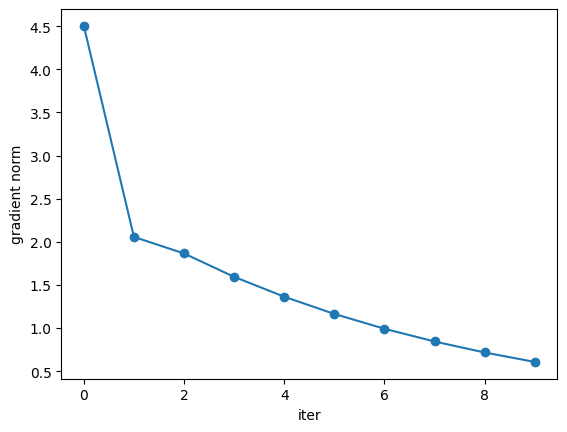

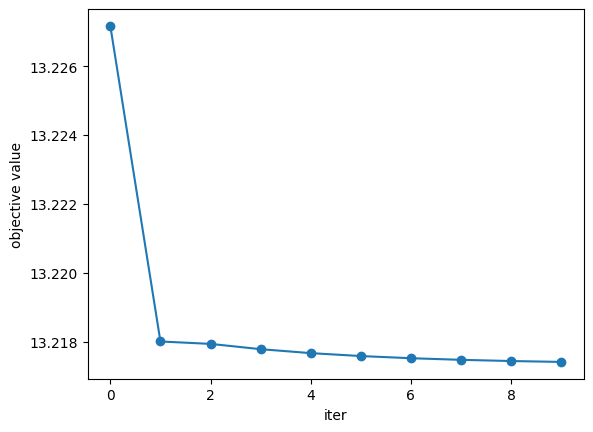

In [31]:
g_vals = results_adult_d4.get('g_vals')
obj_vals = results_adult_d4.get('obj_vals')
print(obj_vals)

plt.plot(g_vals, marker="o")
plt.xlabel("iter")
plt.ylabel("gradient norm")
plt.savefig("adult4x4_1offdiag_grads.png")
plt.show()

plt.plot(obj_vals, marker="o")
plt.xlabel("iter")
plt.ylabel("objective value")
plt.savefig("adult4x4_1offdiag_objvals.png")
plt.show()

# Adult 4x4 chain structure

In [32]:
# data path 
adult_d4_path = "/Users/ceciliaferrando/Documents/UMASS/RESEARCH/DPsynthesisML/hd-datasets-master/clean/adult_d4.csv"

# Run the driver function
results_adult_d4_chain = run_driver(
    data_path=adult_d4_path,
    structure='chain',
    max_iters=10,  # Number of iterations for optimization
    iterative=False  # Non-iterative mode
)

print(results_adult_d4_chain)

       age  workclass  fnlwgt  education
0        8          5       1          9
1       12          1       1          9
2        8          0       4         11
3       13          0       4          1
4        4          0       7          9
...    ...        ...     ...        ...
48837    8          0       4          9
48838   18          8       6         11
48839    8          0       7          9
48840   10          0       1          9
48841    7          2       3          9

[48842 rows x 4 columns]
Sigma_true [[26.54863137  1.12558197 -0.92236391 -0.29460695]
 [ 1.12558197  4.87413218 -0.10834532  0.20117863]
 [-0.92236391 -0.10834532  5.23528579 -0.19909199]
 [-0.29460695  0.20117863 -0.19909199 15.01169162]]
[[0 0]
 [1 1]
 [2 2]
 [3 3]
 [1 0]
 [2 1]
 [3 2]
 [0 1]
 [1 2]
 [2 3]]
inds [[0 0]
 [1 1]
 [2 2]
 [3 3]
 [1 0]
 [2 1]
 [3 2]
 [0 1]
 [1 2]
 [2 3]]
iter: 0, value: 1.3227171e+01
grad sum: 5.732077108071043
Iteration duration: 2.7867 seconds

iter: 1, value: 1.3217409

[Array(13.22717105, dtype=float64), Array(13.21740928, dtype=float64), Array(13.21732877, dtype=float64), Array(13.21715197, dtype=float64), Array(13.21700384, dtype=float64), Array(13.21687729, dtype=float64), Array(13.21677098, dtype=float64), Array(13.21668321, dtype=float64), Array(13.21661162, dtype=float64), Array(13.2165539, dtype=float64)]


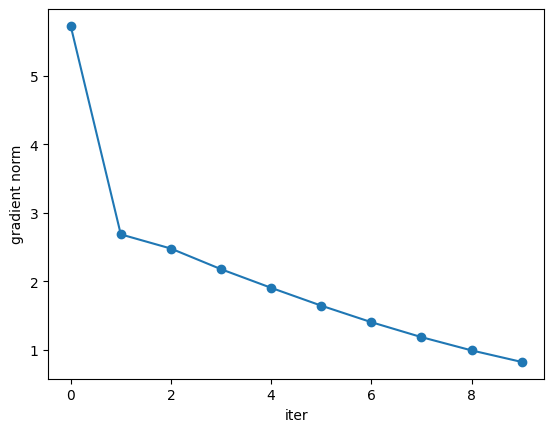

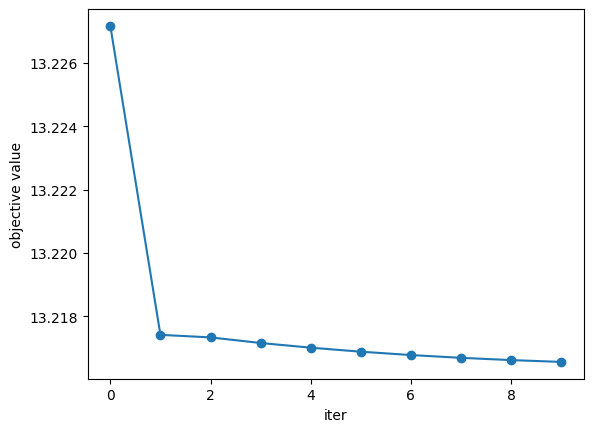

In [33]:
g_vals = results_adult_d4_chain.get('g_vals')
obj_vals = results_adult_d4_chain.get('obj_vals')
print(obj_vals)

plt.plot(g_vals, marker="o")
plt.xlabel("iter")
plt.ylabel("gradient norm")
plt.savefig("adult4x4_1offdiag_grads.png")
plt.show()

plt.plot(obj_vals, marker="o")
plt.xlabel("iter")
plt.ylabel("objective value")
plt.savefig("adult4x4_1offdiag_objvals.png")
plt.show()

# Full Adult - iterative

In [47]:
# data path 
adult_path = "/Users/ceciliaferrando/Documents/UMASS/RESEARCH/DPsynthesisML/hd-datasets-master/clean/adult.csv"

# Run the driver function
results_adult_iter = run_driver(
    data_path=adult_path,
    structure='custom',
    structure_dict=None,
    max_iters=10,  # Number of iterations for optimization
    iterative=True  # Non-iterative mode
)

print(results_adult)

[[ 0  0]
 [ 1  1]
 [ 2  2]
 [ 3  3]
 [ 4  4]
 [ 5  5]
 [ 6  6]
 [ 7  7]
 [ 8  8]
 [ 9  9]
 [10 10]
 [11 11]
 [12 12]
 [13 13]
 [14 14]]
iter: 0, value: 3.6938457e+01
grad sum: 3.5638159090467525e-14
Iteration duration: 2.3053 seconds

iter: 1, value: 3.6938457e+01
grad sum: 1.225519685732479e-11
Iteration duration: 1.9933 seconds

iter: 2, value: 3.6938457e+01
grad sum: 1.0823453244768189e-11
Iteration duration: 1.8771 seconds

iter: 3, value: 3.6938457e+01
grad sum: 9.619083307654819e-12
Iteration duration: 1.7755 seconds

iter: 4, value: 3.6938457e+01
grad sum: 8.436029652614252e-12
Iteration duration: 1.7939 seconds

iter: 5, value: 3.6938457e+01
grad sum: 7.49633688457152e-12
Iteration duration: 4.0293 seconds

iter: 6, value: 3.6938457e+01
grad sum: 6.540656904974185e-12
Iteration duration: 1.8897 seconds

iter: 7, value: 3.6938457e+01
grad sum: 5.805245173462481e-12
Iteration duration: 1.9624 seconds

iter: 8, value: 3.6938457e+01
grad sum: 5.201283848066396e-12
Iteration duratio

KeyboardInterrupt: 